# Weapon-Carrying Risk Prediction — Ensemble Feature Selection with ROC-AUC Sweep

This notebook refines the 38-predictor candidate set produced by the multi-paradigm filter/embedded/wrapper pipeline into a **data-driven optimal subset**. It is written so a reader unfamiliar with the codebase can follow every step.

**Data discipline.** The dataset is split once into **train / validation / test** and each split has a single job:

- **Train** — the only partition used for cross-validation and model fitting.
- **Validation** — used as an independent confirmation after the CV sweep selects `best_n`; never seen during fold training.
- **Test** — completely held out; used only to report the final number.

**The six steps**

1. **Data & feature subset** — load the MICE-imputed dataset and restrict to the 38 consensus predictors.
2. **Stratified three-way split** — train (70 %) / validation (15 %) / test (15 %) with stratification on the rare positive class.
3. **Correlation screening** — inspect pairwise correlations and remove highly redundant predictors (Pearson |r| > 0.80).
4. **VIF screening** — iteratively remove predictors with Variance Inflation Factor > 10 to address multicollinearity.
5. **Multi-model ensemble importance** — average normalized importances from Random Forest, Gradient Boosting, XGBoost, and L1 Logistic Regression across five randomised iterations to produce a robust feature ranking.
6. **Cross-validated ROC-AUC sweep** — evaluate 10-fold stratified CV ROC-AUC as a function of feature count, pick the optimal subset size, and confirm on the held-out validation and test splits.


# 1. Data & Feature Subset

Load the preprocessed, MICE-imputed survey dataset. The 38-predictor `final_list` was assembled by the upstream multi-paradigm feature selection pipeline (`weapon carrying - feature selection.ipynb`) as the union of features identified across six independent selection paradigms (Variance Threshold, ANOVA SelectKBest, Mutual Information, L1 Lasso, Random Forest/XGBoost importances, and Boruta).

Restricting to this candidate pool before any modelling step ensures the downstream ensemble importance and CV sweep operate on a theoretically motivated, pre-screened predictor space.


In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from collections import Counter
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone



import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="xgboost")

In [2]:
data = pd.read_csv('../../data/final_mice_imputed_data_for_feature_selection.csv')
data.head()

,weapon_carrying,U031AD4R,U031PD6R,U031FI1R,U031PS1R,U031SV13,U031SV24R,U031CO1R,U031SV6R,U031MR3R,...,U031WE26_3,U031WE26_5,U031CO9R,U031SR9R,U031AD11R,U031CO2R,U031EI13,U031FC8R,U031BU3R_0_4,U031FI3R
0,0,0,2,3,3,3,0,3,2,3,...,0,0,3,3,2,2,4,3,0,2
1,0,5,2,3,4,4,0,3,3,2,...,1,0,2,3,3,3,3,2,0,2
2,0,0,3,3,3,4,0,3,3,2,...,0,0,3,3,2,3,4,3,0,3
3,0,0,2,3,3,3,0,3,2,2,...,0,0,3,3,2,3,3,3,0,2
4,0,0,3,3,3,2,0,3,3,3,...,0,0,3,4,3,3,4,3,0,3


Weapon carrying is a **low base-rate, high-consequence** outcome. Inspecting the proportion below confirms the severe class imbalance (~4.8 % positive) that motivates class-weighted models and ROC-AUC as the primary evaluation metric throughout this notebook.


In [3]:
 # outcome use
data['weapon_carrying'].value_counts(normalize= True)

weapon_carrying
0    0.951838
1    0.048162
Name: proportion, dtype: float64

Restrict the dataset to the 38 consensus predictors plus the target column. This makes all downstream splits and importance computations operate on the pre-screened feature space only.


In [4]:
# 33 features from basic feature selection method for retaliation
final_list = ['weapon_carrying'] + ['U031D3id_6', 'U031CB2R_binary', 'U031D3id_1', 'U031WE26_4', 'U031WE26_5', 
            'U031WE26_6', 'U031D3id_4', 'U031SV24R', 'U031WE36_binary', 'U031WE37_binary', 'U031SV23R2', 'U031SV20R',
            'U031SV22R', 'U031AD3R2', 'U031SV21R', 'U031AD2R2', 'U031AD5R', 'U031BU4R_0_4', 'U031AD4R', 'U031EI6', 
            'U031D6St', 'U031ScID', 'U031FI3R', 'U031WE13', 'U031SR10R', 'U031WE26_8', 'U031SR6R',
             'U031AE1R', 'U031SV9', 'U031SV8R', 'U031AE5R', 'U031SE1R', 'U031SE2R', 'U031SR4R', 'U031WE24', 'U031FA2R', 'U031CO8R', 'U031CO4R']





data = data[final_list]

# Display the filtered DataFrame
data.head()

,weapon_carrying,U031D3id_6,U031CB2R_binary,U031D3id_1,U031WE26_4,U031WE26_5,U031WE26_6,U031D3id_4,U031SV24R,U031WE36_binary,...,U031SV9,U031SV8R,U031AE5R,U031SE1R,U031SE2R,U031SR4R,U031WE24,U031FA2R,U031CO8R,U031CO4R
0,0,0,1,0,0,0,0,0,0,0,...,2,3,3,3,3,3,3,3,3,2
1,0,0,1,0,0,0,0,0,0,0,...,3,3,4,3,2,3,3,3,3,3
2,0,0,1,0,0,0,0,0,0,0,...,3,4,4,3,3,3,4,3,3,3
3,0,0,1,0,0,0,0,0,0,0,...,2,2,4,3,3,2,3,4,3,3
4,0,0,1,0,0,0,0,0,0,0,...,2,3,3,3,3,3,2,3,3,3


# 2. Stratified Train / Validation / Test Split

`split_data` partitions the data **once** using stratified sampling so the ~4.8 % positive rate is preserved in every partition. The split is fixed at `random_state=12` for reproducibility.

- **Train (70 %)** — used for cross-validation and model fitting.  
- **Validation (15 %)** — independent confirmation after the CV sweep chooses the optimal feature count.  
- **Test (15 %)** — held completely out and used only for the final reported numbers.

Nothing is resampled or fitted on validation or test.


In [5]:

# Helper functions


# ----------------------------
# Train / Val / Test split
# ----------------------------
def split_data(data, target_col="retaliation", test_size=0.30, random_state=12):
    """
    Split original data first.
    - Only the TRAIN split is used for CV + fitting.
    - Validation and Test are kept untouched (no resampling).
    """
    X = data.drop(columns=[target_col])
    y = data[target_col]

    # First split off a temp set (30% of data)
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        stratify=y,
        test_size=test_size,
        random_state=random_state
    )

    # Split temp into Val and Test (15% each if test_size=0.30)
    X_test, X_val, y_test, y_val = train_test_split(
        X_temp, y_temp,
        stratify=y_temp,
        test_size=0.50,
        random_state=random_state
    )

    print("Class counts (original, no resampling):")
    print("Train:", Counter(y_train))
    print("Val:  ", Counter(y_val))
    print("Test: ", Counter(y_test))

    return X_train, X_val, X_test, y_train, y_val, y_test



In [6]:
# create trainvalidation and test
X_train, X_val, X_test, y_train, y_val, y_test = split_data(data, target_col="weapon_carrying")

Class counts (original, no resampling):
Train: Counter({0: 40755, 1: 2062})
Val:   Counter({0: 8734, 1: 442})
Test:  Counter({0: 8733, 1: 442})


# 3. Multicollinearity Screening

## 3.1 Pairwise Correlation Check

Before running importance-based selection, we screen for **redundant predictors** — pairs of features that are so highly correlated that one adds essentially no independent information once the other is included.

`drop_correlated_features` constructs the absolute Pearson correlation matrix, inspects the upper triangle to avoid counting each pair twice, and drops any feature whose correlation with another feature exceeds the threshold (|r| > 0.80). Features are removed from the training set only; the same columns are later dropped from validation and test.


In [7]:
# check correlated ITEMS
def drop_correlated_features(df, threshold=0.8):
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    return df.drop(columns=to_drop), to_drop

# Apply before splitting
filtered_data, dropped = drop_correlated_features(data.drop(columns=['weapon_carrying']))
print(f"Dropped {len(dropped)} redundant features: {dropped}")

Dropped 0 redundant features: []


`get_top_correlations` surfaces the ten most strongly correlated feature pairs to aid interpretation. Reviewing these helps confirm that the threshold is appropriate and that important domain constructs are not being inadvertently removed.


In [8]:
import pandas as pd
import numpy as np

# Assuming 'X_train' is already defined from your previous steps
def get_top_correlations(df, n=10):
    # Calculate absolute correlation matrix
    corr_matrix = df.corr().abs()
    
    # Select the upper triangle of the correlation matrix to avoid duplicates (e.g., A-B and B-A)
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    
    # Stack the matrix and reset index to get pairs
    corr_pairs = upper.unstack().dropna()
    
    # Sort by correlation value in descending order
    sorted_pairs = corr_pairs.sort_values(ascending=False)
    
    return sorted_pairs.head(n)

# Get the top 10 correlated pairs from your training features
top_10_corr = get_top_correlations(X_train)

print("--- TOP 10 CORRELATED FEATURE PAIRS ---")
print(top_10_corr)

--- TOP 10 CORRELATED FEATURE PAIRS ---
U031SE2R   U031SE1R     0.650583
U031AD4R   U031AD2R2    0.647431
U031CO8R   U031SE1R     0.627626
U031AD5R   U031AD3R2    0.615250
U031AD2R2  U031AD3R2    0.605594
U031CO8R   U031AE1R     0.600060
U031AD4R   U031AD5R     0.598611
           U031AD3R2    0.594110
U031AD5R   U031AD2R2    0.592123
U031SE2R   U031AE1R     0.582122
dtype: float64


## 3.2 Variance Inflation Factor (VIF) Screening

Pairwise correlation catches two-way redundancy but misses shared variance distributed across three or more predictors. **VIF** captures this by regressing each feature on all others:

A VIF > 10 (corresponding to $R^2_j > 0.90$) indicates that the predictor is nearly a linear combination of the remaining features and can be safely removed without meaningful information loss.

`calculate_vif` computes VIF for all retained predictors. `recursive_vif_elimination` then iteratively drops the highest-VIF feature and recomputes until all remaining features satisfy VIF ≤ 10.


In [9]:
# Variance Inflation Factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

def calculate_vif(X):
    # VIF requires a constant/intercept to be added for standard results
    X_const = add_constant(X)
    
    vif_data = pd.DataFrame()
    vif_data["feature"] = X.columns
    
    # Calculate VIF for each feature using the matrix that includes the constant
    # get_loc ensures we point to the correct column index in X_const
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, X_const.columns.get_loc(col)) 
                       for col in X.columns]
    
    return vif_data.sort_values(by="VIF", ascending=False)

# Run VIF on your selected features
vif_results = calculate_vif(X_train)
print(vif_results)

            feature       VIF
15        U031AD2R2  2.291196
31         U031SE1R  2.266046
36         U031CO8R  2.251434
18         U031AD4R  2.168470
16         U031AD5R  2.140006
32         U031SE2R  2.094318
27         U031AE1R  2.045763
13        U031AD3R2  2.029196
3        U031WE26_4  1.751661
33         U031SR4R  1.727651
4        U031WE26_5  1.702552
20         U031D6St  1.675821
5        U031WE26_6  1.586533
37         U031CO4R  1.561485
14        U031SV21R  1.545636
11        U031SV20R  1.523227
12        U031SV22R  1.505433
21         U031ScID  1.487415
29         U031SV8R  1.473119
30         U031AE5R  1.449748
24        U031SR10R  1.429330
22         U031FI3R  1.401190
7         U031SV24R  1.392598
8   U031WE36_binary  1.390895
26         U031SR6R  1.375428
10       U031SV23R2  1.369977
19          U031EI6  1.369906
9   U031WE37_binary  1.363019
17     U031BU4R_0_4  1.337527
34         U031WE24  1.289693
35         U031FA2R  1.258246
28          U031SV9  1.245494
25       U

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def recursive_vif_elimination(X, threshold=10.0):
    current_X = X.copy()
    
    while True:
        # Standardize the calculation by adding a constant
        X_const = add_constant(current_X)
        
        vif_data = pd.DataFrame()
        vif_data["feature"] = current_X.columns
        vif_data["VIF"] = [variance_inflation_factor(X_const.values, X_const.columns.get_loc(col)) 
                           for col in current_X.columns]
        
        max_vif = vif_data["VIF"].max()
        if max_vif <= threshold:
            break
            
        feature_to_drop = vif_data.sort_values("VIF", ascending=False).iloc[0]["feature"]
        print(f"Dropping '{feature_to_drop}' with VIF: {max_vif:.2f}")
        
        current_X = current_X.drop(columns=[feature_to_drop])
        
    return current_X.columns.tolist()

# Apply to your training set to identify features to keep
final_vif_features = recursive_vif_elimination(X_train, threshold=10.0)

print("\nFinal Parsemonious Feature Set:", final_vif_features)


Final Parsemonious Feature Set: ['U031D3id_6', 'U031CB2R_binary', 'U031D3id_1', 'U031WE26_4', 'U031WE26_5', 'U031WE26_6', 'U031D3id_4', 'U031SV24R', 'U031WE36_binary', 'U031WE37_binary', 'U031SV23R2', 'U031SV20R', 'U031SV22R', 'U031AD3R2', 'U031SV21R', 'U031AD2R2', 'U031AD5R', 'U031BU4R_0_4', 'U031AD4R', 'U031EI6', 'U031D6St', 'U031ScID', 'U031FI3R', 'U031WE13', 'U031SR10R', 'U031WE26_8', 'U031SR6R', 'U031AE1R', 'U031SV9', 'U031SV8R', 'U031AE5R', 'U031SE1R', 'U031SE2R', 'U031SR4R', 'U031WE24', 'U031FA2R', 'U031CO8R', 'U031CO4R']


After elimination, apply the retained feature list to create the filtered dataset and re-run the three-way split on the cleaner predictor space.


In [11]:
# Create the final list including the target variable
final_columns = ['weapon_carrying'] + final_vif_features

# Filter the original data to drop the redundant items
filtered_data = data[final_columns]

print(f"Analysis will proceed with {len(final_vif_features)} features.")
filtered_data.head()

Analysis will proceed with 38 features.


,weapon_carrying,U031D3id_6,U031CB2R_binary,U031D3id_1,U031WE26_4,U031WE26_5,U031WE26_6,U031D3id_4,U031SV24R,U031WE36_binary,...,U031SV9,U031SV8R,U031AE5R,U031SE1R,U031SE2R,U031SR4R,U031WE24,U031FA2R,U031CO8R,U031CO4R
0,0,0,1,0,0,0,0,0,0,0,...,2,3,3,3,3,3,3,3,3,2
1,0,0,1,0,0,0,0,0,0,0,...,3,3,4,3,2,3,3,3,3,3
2,0,0,1,0,0,0,0,0,0,0,...,3,4,4,3,3,3,4,3,3,3
3,0,0,1,0,0,0,0,0,0,0,...,2,2,4,3,3,2,3,4,3,3
4,0,0,1,0,0,0,0,0,0,0,...,2,3,3,3,3,3,2,3,3,3


In [12]:
# final dataset for feature evaluation
# create trainvalidation and test
X_train_final, X_val_final, X_test_final, y_train_final, y_val_final, y_test_final = split_data(filtered_data, target_col="weapon_carrying")

Class counts (original, no resampling):
Train: Counter({0: 40755, 1: 2062})
Val:   Counter({0: 8734, 1: 442})
Test:  Counter({0: 8733, 1: 442})


Confirm the training matrix dimensions after VIF filtering.


In [13]:
X_train_final.shape

(42817, 38)

# 4. Multi-Model Ensemble Feature Importance

Relying on a single model's feature importances can be biased by that model's inductive assumptions (e.g., Random Forest MDI inflates importance of high-cardinality features; XGBoost split-gain favours features that appear in many shallow trees). Averaging across diverse model families reduces this bias.

The ensemble averages **normalized** importances from four model families:

| Model | Importance Metric | Imbalance Handling |
| :--- | :--- | :--- |
| Random Forest (RF) | Mean Decrease in Impurity (Gini) | `class_weight="balanced"` |
| Gradient Boosting (GBC) | Split gain | `sample_weight` (balanced) |
| XGBoost (XGB) | Split gain | `scale_pos_weight` |
| L1 Logistic Regression (LR) | Absolute coefficient magnitude | `class_weight="balanced"` |

Five randomised iterations with different seeds average out initialization noise. Within each iteration, per-model importances are normalized to sum to 1 before averaging, so no model family dominates by scale.

`get_ensemble_models` initializes all four classifiers with device-appropriate settings. `compute_ensemble_feature_importance` runs the five-iteration loop and returns a ranked importance DataFrame.


In [14]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

def get_ensemble_models(random_state, pos_weight, use_gpu=False):
    """Initializes models with appropriate imbalance handling and GPU settings."""
    tree_method = "hist"
    device = "cpu"

    if use_gpu:
        # Modern XGBoost (2.0+) uses device="cuda"
        # Older versions use tree_method="gpu_hist"
        tree_method = "gpu_hist" 
        device = "cuda"

    models = {
        "rf": RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=random_state,
            n_jobs=-1
        ),
        "gbc": GradientBoostingClassifier(
            n_estimators=300,
            random_state=random_state
        ),
        "xgb": XGBClassifier(
            n_estimators=300,
            random_state=random_state,
            eval_metric="auc",
            scale_pos_weight=pos_weight,
            tree_method=tree_method,
            device=device
        ),
        "lr": LogisticRegression(
            class_weight="balanced",
            random_state=random_state,
            max_iter=1000,
            solver='liblinear'
        )
    }
    return models

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

def compute_ensemble_feature_importance(X, y, n_iterations=5, random_state=42, use_gpu=False):
    pos_weight = float(len(y) - np.sum(y)) / max(float(np.sum(y)), 1.0)
    agg_importances = pd.DataFrame(index=X.columns)
    
    # Scale for Logistic Regression
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

    for i in range(n_iterations):
        print(f"--- Iteration {i+1}/{n_iterations} ---")
        current_state = random_state + i
        models = get_ensemble_models(current_state, pos_weight, use_gpu)
        importances = {}

        for name, model in models.items():
            try:
                if name == "gbc":
                    sw = compute_sample_weight(class_weight="balanced", y=y)
                    model.fit(X, y, sample_weight=sw)
                    importances[name] = model.feature_importances_
                elif name == "lr":
                    model.fit(X_scaled, y)
                    importances[name] = np.abs(model.coef_[0])
                else:
                    model.fit(X, y)
                    importances[name] = model.feature_importances_
            except Exception as e:
                print(f"Warning: {name} failed on iteration {i}. Error: {e}")
                continue
        
        # Normalize and store iteration average
        iter_df = pd.DataFrame(importances, index=X.columns)
        iter_df = iter_df.div(iter_df.sum(axis=0), axis=1)
        agg_importances[f'iter_{i}'] = iter_df.mean(axis=1)

    agg_importances["ensemble_importance"] = agg_importances.mean(axis=1)
    return agg_importances.sort_values("ensemble_importance", ascending=False)

`get_top_n_features_by_ensemble` wraps the above to return the top-N feature names alongside the full importance table for later use.


In [16]:
def get_top_n_features_by_ensemble(X, y, top_n=20, n_iterations=5, random_state=42, use_gpu=False):
    """Wrapper to compute importance and return the top-N feature names."""
    importance_df = compute_ensemble_feature_importance(
        X, y, n_iterations=n_iterations, random_state=random_state, use_gpu=use_gpu
    )
    
    top_features = importance_df.head(top_n).index.tolist()
    print(f"\nTop {top_n} features selected.")
    return top_features, importance_df

Execute the ensemble importance computation on the VIF-filtered training set. Setting `top_n=15` returns the 15 highest-ranked predictors for the sweep in the next section.


In [17]:
# Execute feature selection
top_features, importance_df = get_top_n_features_by_ensemble(
    X_train_final,
    y_train_final,
    top_n=15,
    random_state=42,
    use_gpu=False  # Set to False if no CUDA-compatible GPU is present
)

# Subset your datasets
X_train_sel = X_train_final[top_features]
X_val_sel = X_val_final[top_features]
X_test_sel = X_test_final[top_features]

--- Iteration 1/5 ---
--- Iteration 2/5 ---
--- Iteration 3/5 ---
--- Iteration 4/5 ---
--- Iteration 5/5 ---

Top 15 features selected.


# 5. Cross-Validated Feature-Count Sweep

## 5.1 Sweep Design

With features ranked by ensemble importance, the question becomes: **how many top features should be retained?** Adding more features beyond a certain point yields diminishing or negative returns (overfitting, correlated noise).

The sweep below evaluates **cross-validated ROC-AUC** — not a single train/validation split — as a function of feature count. Using `StratifiedKFold` (stratified because the outcome is imbalanced) means every measurement is a mean ± std over *k* folds rather than a single point estimate, making the elbow in the curve much more reliable.

`choose_cv_folds` picks 5 or 10 folds automatically based on the minority-class size: 10 folds when there are enough positive cases per fold for a stable ROC-AUC estimate, 5 folds otherwise.

`feature_count` runs the sweep: for each step value it selects the top-*n* ranked features, runs `cross_val_score`, and records the mean ± std ROC-AUC.


In [18]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from collections import Counter


def choose_cv_folds(y, min_positives_for_10=100, default_folds=10):
    """
    Pick the number of CV folds based on the task.

    For an imbalanced binary target the binding constraint is the size of the
    minority class: StratifiedKFold needs at least ``n_splits`` samples of the
    smallest class, and each held-out fold needs enough positives for a stable
    ROC-AUC.

        * 10 folds when the minority class is large enough that every fold
          still holds a healthy number of positives.
        * otherwise 5 folds (the robust default for smaller / more imbalanced
          data).
        * never more folds than there are minority-class samples (a hard
          StratifiedKFold requirement).
    """
    counts = Counter(y)
    minority = min(counts.values())
    desired = 10 if minority >= min_positives_for_10 else default_folds
    folds = min(desired, minority)
    if folds < 2:
        raise ValueError(
            f"Only {minority} sample(s) in the minority class — too few for cross-validation."
        )
    if folds != desired:
        print(f"[cv] minority class has {minority} samples -> using {folds} folds "
              f"(requested {desired}).")
    return folds


def feature_count(model, X, y, ranked_features,
                  steps=[5, 10, 15, 20, 25, 30, 35],
                  cv=None, random_state=42):
    """
    Evaluate how *cross-validated* ROC-AUC changes with the number of features.

    Instead of fitting once and scoring on a single validation split, this uses
    StratifiedKFold cross-validation (stratified because the target is
    imbalanced) and reports the mean +/- std ROC-AUC across folds for each
    feature-count step.

    Parameters
    ----------
    model : estimator
        Any classifier exposing predict_proba / decision_function. It is cloned
        inside cross_val_score, so the passed object is never mutated.
    X, y : development data to cross-validate on (keep the test set separate).
    ranked_features : features ordered best -> worst (e.g. importance_df.index).
    steps : feature counts to try.
    cv : int or None. Number of folds; if None it is chosen from the data by
        ``choose_cv_folds`` (5 or 10 depending on the minority-class size).
    random_state : seed for reproducible, shuffled folds.
    """
    n_splits = cv if cv is not None else choose_cv_folds(y)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    print(f"Cross-validating with StratifiedKFold(n_splits={n_splits}, shuffle=True)\n")

    # never request more features than we actually have
    valid_steps = [n for n in steps if n <= len(ranked_features)]

    results = []
    for n in valid_steps:
        selected_features = ranked_features[:n]

        fold_scores = cross_val_score(
            model,
            X[selected_features], y,
            cv=skf,
            scoring="roc_auc",
        )

        results.append({
            "n_features": n,
            "roc_auc_mean": fold_scores.mean(),
            "roc_auc_std": fold_scores.std(),
            "fold_scores": fold_scores,
        })
        print(f"{n:>2} features -> ROC-AUC: {fold_scores.mean():.4f} +/- {fold_scores.std():.4f}")

    return pd.DataFrame(results)

Run the sweep on the VIF-filtered training set across the feature-count steps. The validation and test sets are kept completely separate — they are used only after `best_n` is chosen.


In [19]:
# ---------------------------------------------------------------
# Cross-validated feature-count sweep.
#
# We cross-validate on the TRAINING set with StratifiedKFold (stratified
# because the target is imbalanced). The number of folds (5 or 10) is
# chosen automatically from the minority-class size; pass cv=5 or cv=10
# to fix it manually. The validation and test sets stay held out and are
# used in the next cell as independent confirmation.
# ---------------------------------------------------------------
df_roc = feature_count(
    model=RandomForestClassifier(n_estimators=300, random_state=42),
    X=X_train_final,
    y=y_train_final,
    ranked_features=importance_df.index.tolist(),
    cv=10,          # -> 5 or 10, chosen from the data
    random_state=42,
)

df_roc

Cross-validating with StratifiedKFold(n_splits=10, shuffle=True)

 5 features -> ROC-AUC: 0.8518 +/- 0.0147
10 features -> ROC-AUC: 0.8641 +/- 0.0088
15 features -> ROC-AUC: 0.9041 +/- 0.0093
20 features -> ROC-AUC: 0.9076 +/- 0.0067
25 features -> ROC-AUC: 0.9081 +/- 0.0066
30 features -> ROC-AUC: 0.9087 +/- 0.0084
35 features -> ROC-AUC: 0.9094 +/- 0.0085


,n_features,roc_auc_mean,roc_auc_std,fold_scores
0,5,0.851761,0.014683,"[0.8804802204712405, 0.8625323942185849, 0.835..."
1,10,0.864052,0.008794,"[0.8768346799165373, 0.8655294549196337, 0.847..."
2,15,0.904107,0.009309,"[0.9173089932067419, 0.8985745352858789, 0.902..."
3,20,0.907621,0.006731,"[0.9173447221242985, 0.9063765399163466, 0.910..."
4,25,0.908098,0.006629,"[0.9187000390636165, 0.9105079937498214, 0.904..."
5,30,0.908718,0.008416,"[0.9240778366378611, 0.9146900635498348, 0.907..."
6,35,0.909353,0.008456,"[0.9277019398420306, 0.9113523871680783, 0.902..."


Plot the cross-validated ROC-AUC curve. The shaded band shows ± 1 standard deviation across folds. The optimal feature count (`best_n`) is the point that maximises the mean CV ROC-AUC.


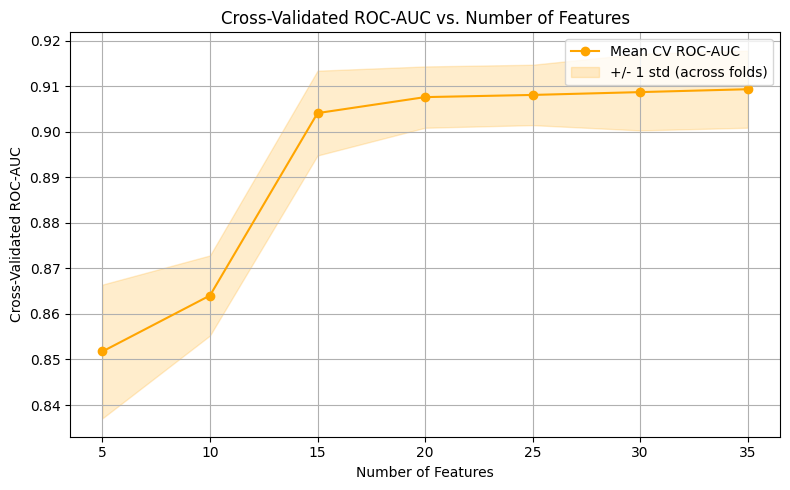

In [20]:
import matplotlib.pyplot as plt

# best feature count by mean cross-validated ROC-AUC
best_row = df_roc.loc[df_roc["roc_auc_mean"].idxmax()]
best_n = int(best_row["n_features"])

plt.figure(figsize=(8, 5))
plt.plot(df_roc["n_features"], df_roc["roc_auc_mean"],
         marker="o", color="orange", label="Mean CV ROC-AUC")
plt.fill_between(
    df_roc["n_features"],
    df_roc["roc_auc_mean"] - df_roc["roc_auc_std"],
    df_roc["roc_auc_mean"] + df_roc["roc_auc_std"],
    color="orange", alpha=0.2, label="+/- 1 std (across folds)",
)
#plt.axvline(best_n, color="gray", linestyle="--", alpha=0.7,
#            label=f"Best: {best_n} features")
plt.title("Cross-Validated ROC-AUC vs. Number of Features")
plt.xlabel("Number of Features")
plt.ylabel("Cross-Validated ROC-AUC")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("roc_auc_vs_features_ensemble II.png", dpi=300)
plt.show()

## 5.2 Refit at Optimal Feature Count & Independent Holdout Confirmation

Having identified `best_n` purely through cross-validation on the training set, we now:

1. Refit a Random Forest on the full training set using only the `best_n` top features.
2. Score on the **validation set** — an independent check that was never seen during the CV sweep.
3. Score on the **test set** — the final, once-only report number.

Concordance between the CV ROC-AUC, validation ROC-AUC, and test ROC-AUC indicates that the feature-count choice generalises beyond the training folds.


In [21]:
# ---------------------------------------------------------------
# Refit at the best feature count and confirm on the held-out splits.
#   * Cross-validated ROC-AUC (from the sweep) is the SELECTION metric.
#   * Validation / Test ROC-AUC are independent, out-of-sample checks
#     (these splits were not involved in cross-validation).
# ---------------------------------------------------------------
best_features = importance_df.index.tolist()[:best_n]

final_model = RandomForestClassifier(n_estimators=300, random_state=42)
final_model.fit(X_train_final[best_features], y_train_final)

val_auc = roc_auc_score(
    y_val_final, final_model.predict_proba(X_val_final[best_features])[:, 1]
)
test_auc = roc_auc_score(
    y_test_final, final_model.predict_proba(X_test_final[best_features])[:, 1]
)

print(f"Best feature count (by CV): {best_n}")
print(f"Cross-validated ROC-AUC   : {best_row['roc_auc_mean']:.4f} +/- {best_row['roc_auc_std']:.4f}")
print(f"Validation ROC-AUC        : {val_auc:.4f}")
print(f"Held-out TEST ROC-AUC     : {test_auc:.4f}")

Best feature count (by CV): 35
Cross-validated ROC-AUC   : 0.9094 +/- 0.0085
Validation ROC-AUC        : 0.9251
Held-out TEST ROC-AUC     : 0.9149
